In [9]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables.history import RunnableWithMessageHistory
from langchain_core.messages import HumanMessage, AIMessage

load_dotenv()

True

In [10]:
#every input need to be tagged as a human message

#langchain automatically put the inputs as humanmessage

#message placeholder is desigend for 

In [11]:
llm = ChatOpenAI(model="gpt-4o-mini")
llm.invoke('hi')

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_eb86cfd659', 'id': 'chatcmpl-EijTyCiUlIbbV0XytIfZ8jmVuJdmy', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1c666-9354-75d8-852d-4d70cfce8c63-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [12]:
history= InMemoryChatMessageHistory()
history.messages

[]

In [13]:
# prompt _> role, input, output

In [14]:
# lets create the prompt

prompt = ChatPromptTemplate.from_messages([
    ("system", """\
        You are a professional email support agent.
        Classify complaints as: Billing / Technical / General.
        Priority: High (financial impact > $100 or urgent) / Medium / Low.
        Remember all customer details throughout the conversation."""),
    MessagesPlaceholder(variable_name="history"),  # ← past turns injected here
    ("human", "{input}"),                           # ← new message here
])
# step 2 LCEL

chain= prompt |llm |StrOutputParser()

memory should be created based on the sessionid
for each user the memory shold be separate

In [15]:
store ={}

def get_session_history(session_id):
    if session_id not in store:
        store[session_id]= InMemoryChatMessageHistory()
    return store[session_id]

In [16]:
get_session_history("sharad")

InMemoryChatMessageHistory(messages=[])

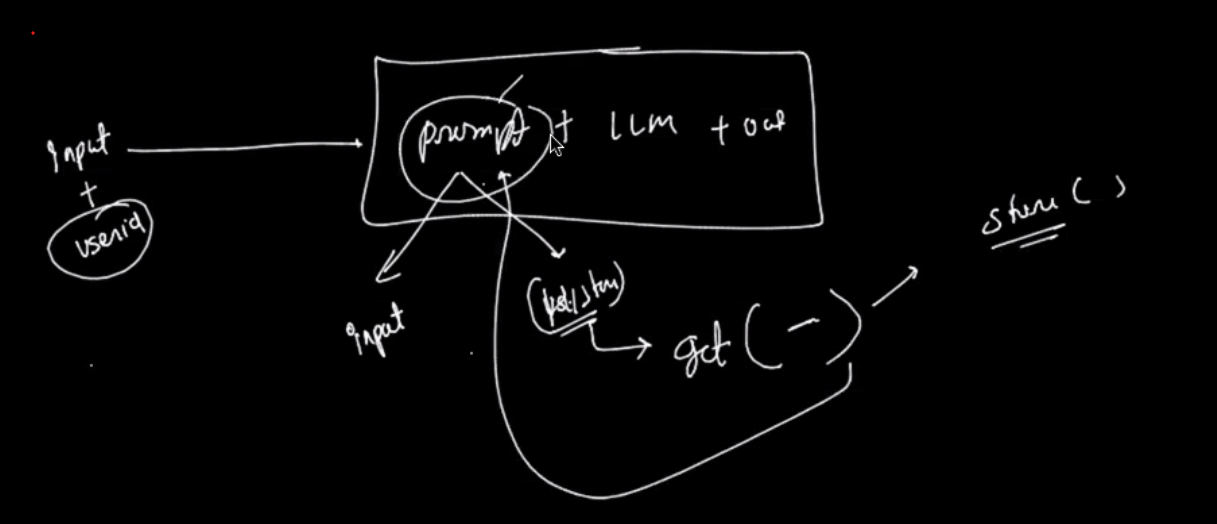

In [17]:
agent = RunnableWithMessageHistory(
    chain, get_session_history, input_messages_key="input", history_messages_key="history"
)

In [18]:
cfg = {"configurable":{"session_id":"sharad_1"}}

In [19]:
r1 = agent.invoke({"input": "I received a billing complaint from John about invoice #1042. He was charged $500 instead of $250."},
                            config=cfg)

In [20]:
r2 = agent.invoke(    {"input": "What category does his complaint fall under?"},    config=cfg)

In [21]:
r2

"John's complaint falls under the category of Billing."

In [23]:
store['sharad_1']

InMemoryChatMessageHistory(messages=[HumanMessage(content='I received a billing complaint from John about invoice #1042. He was charged $500 instead of $250.', additional_kwargs={}, response_metadata={}), AIMessage(content='Complaint Classification: Billing  \nPriority: High  \n\nCustomer Details:  \n- Name: John  \n- Invoice Number: #1042  \n- Issue: Charged $500 instead of $250  ', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='What category does his complaint fall under?', additional_kwargs={}, response_metadata={}), AIMessage(content="John's complaint falls under the category of Billing.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])])

In [24]:
cfg = {"configurable":{"session_id":"shubham_321"}}
agent.invoke(
    {"input": "What category does his complaint fall under?"},
    config=cfg
)

'Please provide me with the details of the complaint so that I can assist you in classifying it accordingly.'

In [25]:
store

{'sharad': InMemoryChatMessageHistory(messages=[]),
 'sharad_1': InMemoryChatMessageHistory(messages=[HumanMessage(content='I received a billing complaint from John about invoice #1042. He was charged $500 instead of $250.', additional_kwargs={}, response_metadata={}), AIMessage(content='Complaint Classification: Billing  \nPriority: High  \n\nCustomer Details:  \n- Name: John  \n- Invoice Number: #1042  \n- Issue: Charged $500 instead of $250  ', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='What category does his complaint fall under?', additional_kwargs={}, response_metadata={}), AIMessage(content="John's complaint falls under the category of Billing.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]),
 'shubham_321': InMemoryChatMessageHistory(messages=[HumanMessage(content='What category does his complaint fall under?', additional_kwargs={}, response_metadata={}), AIMessage(content='Pleas

In [26]:
get_session_history('sharad')

InMemoryChatMessageHistory(messages=[])

In [27]:
store

{'sharad': InMemoryChatMessageHistory(messages=[]),
 'sharad_1': InMemoryChatMessageHistory(messages=[HumanMessage(content='I received a billing complaint from John about invoice #1042. He was charged $500 instead of $250.', additional_kwargs={}, response_metadata={}), AIMessage(content='Complaint Classification: Billing  \nPriority: High  \n\nCustomer Details:  \n- Name: John  \n- Invoice Number: #1042  \n- Issue: Charged $500 instead of $250  ', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='What category does his complaint fall under?', additional_kwargs={}, response_metadata={}), AIMessage(content="John's complaint falls under the category of Billing.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]),
 'shubham_321': InMemoryChatMessageHistory(messages=[HumanMessage(content='What category does his complaint fall under?', additional_kwargs={}, response_metadata={}), AIMessage(content='Pleas

In [28]:
get_session_history('raman')

InMemoryChatMessageHistory(messages=[])

In [29]:
history.add_user_message("my name is rahul")

In [30]:
history.add_ai_message("Undrstood you query but I can thelp you")

In [31]:
history.add_user_message("I have a billing issue")
history.add_ai_message("Undrstood you query but I can thelp you")

In [32]:
history.messages

[HumanMessage(content='my name is rahul', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Undrstood you query but I can thelp you', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='I have a billing issue', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Undrstood you query but I can thelp you', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]